<a href="https://colab.research.google.com/github/english075social/Clase80/blob/main/Clasificaci%C3%B3n_cultivos2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
## 🔄 Versión con Datos Realistas (AgroTech Auténtico)

En esta sección, generamos datos basados en los rangos biológicos reales del dataset estándar de recomendación de cultivos:
* **Arroz**: Requiere alta humedad (80-95%), mucha lluvia (1500-2500 mm) y temperaturas cálidas.
* **Maíz**: Requiere humedad moderada (55-70%), lluvia moderada (500-1000 mm) y pH neutro.
* **Trigo**: Tolera climas más secos (humedad 30-50%), menos lluvia (300-600 mm) y temperaturas templadas o frescas.
```

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Fijamos la semilla para reproducibilidad
np.random.seed(42)
muestras_por_cultivo = 100

# --- Simulación de Datos Biológicamente Realistas ---

# Datos para el Arroz (Clima Tropical/Húmedo)
ph_arroz = np.random.uniform(5.5, 7.0, muestras_por_cultivo)
humedad_arroz = np.random.uniform(80.0, 95.0, muestras_por_cultivo)
tipo_suelo_arroz = np.random.choice(["Arcilloso", "Limoso"], muestras_por_cultivo, p=[0.7, 0.3])
temperatura_arroz = np.random.uniform(22.0, 32.0, muestras_por_cultivo)
precipitacion_arroz = np.random.uniform(1500.0, 2500.0, muestras_por_cultivo)
horas_sol_arroz = np.random.uniform(5.0, 7.5, muestras_por_cultivo)
cultivo_arroz = ["Arroz"] * muestras_por_cultivo

# Datos para el Maíz (Clima Templado/Cálido moderado)
ph_maiz = np.random.uniform(5.8, 7.2, muestras_por_cultivo)
humedad_maiz = np.random.uniform(55.0, 75.0, muestras_por_cultivo)
tipo_suelo_maiz = np.random.choice(["Limoso", "Arcilloso", "Arenoso"], muestras_por_cultivo, p=[0.5, 0.3, 0.2])
temperatura_maiz = np.random.uniform(18.0, 28.0, muestras_por_cultivo)
precipitacion_maiz = np.random.uniform(600.0, 1100.0, muestras_por_cultivo)
horas_sol_maiz = np.random.uniform(7.0, 9.0, muestras_por_cultivo)
cultivo_maiz = ["Maíz"] * muestras_por_cultivo

# Datos para el Trigo (Clima Templado/Seco)
ph_trigo = np.random.uniform(6.0, 7.5, muestras_por_cultivo)
humedad_trigo = np.random.uniform(35.0, 55.0, muestras_por_cultivo)
tipo_suelo_trigo = np.random.choice(["Arenoso", "Limoso"], muestras_por_cultivo, p=[0.6, 0.4])
temperatura_trigo = np.random.uniform(12.0, 22.0, muestras_por_cultivo)
precipitacion_trigo = np.random.uniform(350.0, 700.0, muestras_por_cultivo)
horas_sol_trigo = np.random.uniform(6.5, 8.5, muestras_por_cultivo)
cultivo_trigo = ["Trigo"] * muestras_por_cultivo

# Concatenamos todo en un DataFrame estructurado
df_realista = pd.DataFrame({
    "ph_suelo": np.concatenate([ph_arroz, ph_maiz, ph_trigo]),
    "humedad": np.concatenate([humedad_arroz, humedad_maiz, humedad_trigo]),
    "tipo_suelo": np.concatenate([tipo_suelo_arroz, tipo_suelo_maiz, tipo_suelo_trigo]),
    "temperatura": np.concatenate([temperatura_arroz, temperatura_maiz, temperatura_trigo]),
    "precipitacion": np.concatenate([precipitacion_arroz, precipitacion_maiz, precipitacion_trigo]),
    "horas_sol": np.concatenate([horas_sol_arroz, horas_sol_maiz, horas_sol_trigo]),
    "tipo_de_cultivo": np.concatenate([cultivo_arroz, cultivo_maiz, cultivo_trigo])
})

print("✅ ¡Dataset realista estructurado con éxito!")
display(df_realista.sample(5))

✅ ¡Dataset realista estructurado con éxito!


,ph_suelo,humedad,tipo_suelo,temperatura,precipitacion,horas_sol,tipo_de_cultivo
116,5.885509,71.612388,Arcilloso,20.944658,690.287673,7.182974,Maíz
155,5.978612,70.880504,Limoso,21.831385,775.355908,8.505433,Maíz
90,5.679391,81.396542,Arcilloso,31.905051,1955.656753,5.347068,Arroz
42,5.551583,87.458728,Limoso,23.732019,1874.270796,5.571607,Arroz
250,7.194806,52.340630,Arenoso,21.514033,362.656133,7.570620,Trigo


📊 Precisión Árbol de Decisión : 100.00%
📊 Precisión Random Forest     : 100.00%

📋 Reporte de clasificación detallado (Random Forest):
              precision    recall  f1-score   support

       Arroz       1.00      1.00      1.00        20
        Maíz       1.00      1.00      1.00        20
       Trigo       1.00      1.00      1.00        20

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



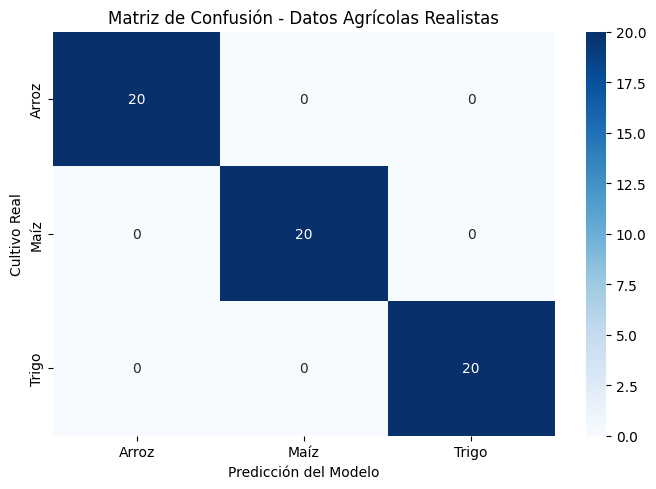


🌾 Relevancia real de las variables para los cultivos:
  • humedad               : 42.45% de relevancia
  • precipitacion         : 34.77% de relevancia
  • temperatura           : 10.81% de relevancia
  • horas_sol             : 8.59% de relevancia
  • tipo_suelo_codificado : 2.34% de relevancia
  • ph_suelo              : 1.05% de relevancia


In [19]:
# ==============================================================================
# PIPELINE DE MACHINE LEARNING - CLASIFICACIÓN AGRÍCOLA (PROYECTO 3)
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Aseguramos la importación de todas las herramientas de scikit-learn necesarias
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# --- GENERACIÓN INTERNA DE DATOS SIMULADOS REALISTAS ---
# De esta forma garantizamos que 'df_realista' exista en memoria sin depender de otras celdas
np.random.seed(42)
muestras_por_cultivo = 100

# Datos para el Arroz (Clima Tropical/Húmedo)
ph_arroz = np.random.uniform(5.5, 7.0, muestras_por_cultivo)
humedad_arroz = np.random.uniform(80.0, 95.0, muestras_por_cultivo)
tipo_suelo_arroz = np.random.choice(["Arcilloso", "Limoso"], muestras_por_cultivo, p=[0.7, 0.3])
temperatura_arroz = np.random.uniform(22.0, 32.0, muestras_por_cultivo)
precipitacion_arroz = np.random.uniform(1500.0, 2500.0, muestras_por_cultivo)
horas_sol_arroz = np.random.uniform(5.0, 7.5, muestras_por_cultivo)
cultivo_arroz = ["Arroz"] * muestras_por_cultivo

# Datos para el Maíz (Clima Templado/Cálido moderado)
ph_maiz = np.random.uniform(5.8, 7.2, muestras_por_cultivo)
humedad_maiz = np.random.uniform(55.0, 75.0, muestras_por_cultivo)
tipo_suelo_maiz = np.random.choice(["Limoso", "Arcilloso", "Arenoso"], muestras_por_cultivo, p=[0.5, 0.3, 0.2])
temperatura_maiz = np.random.uniform(18.0, 28.0, muestras_por_cultivo)
precipitacion_maiz = np.random.uniform(600.0, 1100.0, muestras_por_cultivo)
horas_sol_maiz = np.random.uniform(7.0, 9.0, muestras_por_cultivo)
cultivo_maiz = ["Maíz"] * muestras_por_cultivo

# Datos para el Trigo (Clima Templado/Seco)
ph_trigo = np.random.uniform(6.0, 7.5, muestras_por_cultivo)
humedad_trigo = np.random.uniform(35.0, 55.0, muestras_por_cultivo)
tipo_suelo_trigo = np.random.choice(["Arenoso", "Limoso"], muestras_por_cultivo, p=[0.6, 0.4])
temperatura_trigo = np.random.uniform(12.0, 22.0, muestras_por_cultivo)
precipitacion_trigo = np.random.uniform(350.0, 700.0, muestras_por_cultivo)
horas_sol_trigo = np.random.uniform(6.5, 8.5, muestras_por_cultivo)
cultivo_trigo = ["Trigo"] * muestras_por_cultivo

df_realista = pd.DataFrame({
    "ph_suelo": np.concatenate([ph_arroz, ph_maiz, ph_trigo]),
    "humedad": np.concatenate([humedad_arroz, humedad_maiz, humedad_trigo]),
    "tipo_suelo": np.concatenate([tipo_suelo_arroz, tipo_suelo_maiz, tipo_suelo_trigo]),
    "temperatura": np.concatenate([temperatura_arroz, temperatura_maiz, temperatura_trigo]),
    "precipitacion": np.concatenate([precipitacion_arroz, precipitacion_maiz, precipitacion_trigo]),
    "horas_sol": np.concatenate([horas_sol_arroz, horas_sol_maiz, horas_sol_trigo]),
    "tipo_de_cultivo": np.concatenate([cultivo_arroz, cultivo_maiz, cultivo_trigo])
})

# 1. PREPROCESAMIENTO: Codificación de variables categóricas (tipo_suelo)
codificador_suelo_r = LabelEncoder()
df_realista["tipo_suelo_codificado"] = codificador_suelo_r.fit_transform(df_realista["tipo_suelo"])

# Definimos variables de entrada (X) y variable objetivo (y)
X_r = df_realista.drop(columns=["tipo_suelo", "tipo_de_cultivo"])
y_r = df_realista["tipo_de_cultivo"]

# 2. DIVISIÓN DE DATOS: 80% Entrenamiento y 20% Prueba (estratificado por clase)
X_ent_r, X_pru_r, y_ent_r, y_pru_r = train_test_split(
    X_r, y_r, test_size=0.2, random_state=42, stratify=y_r
)

# 3. NORMALIZACIÓN: Escalado de características numéricas
escalador_r = StandardScaler()
X_ent_r_esc = escalador_r.fit_transform(X_ent_r)
X_pru_r_esc = escalador_r.transform(X_pru_r)

# 4. ENTRENAMIENTO DE DOS MODELOS DE CLASIFICACIÓN
# Modelo A: Árbol de Decisión
modelo_arbol_r = DecisionTreeClassifier(max_depth=4, random_state=42)
modelo_arbol_r.fit(X_ent_r_esc, y_ent_r)

# Modelo B: Random Forest (Bosque Aleatorio)
modelo_bosque_r = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_bosque_r.fit(X_ent_r_esc, y_ent_r)

# 5. EVALUACIÓN Y MÉTRICAS
pred_arbol_r = modelo_arbol_r.predict(X_pru_r_esc)
pred_bosque_r = modelo_bosque_r.predict(X_pru_r_esc)

precision_arbol = accuracy_score(y_pru_r, pred_arbol_r) * 100
precision_bosque = accuracy_score(y_pru_r, pred_bosque_r) * 100

print("===================================================================")
print(f"📊 Precisión Árbol de Decisión : {precision_arbol:.2f}%")
print(f"📊 Precisión Random Forest     : {precision_bosque:.2f}%")
print("===================================================================\n")

print("📋 Reporte de clasificación detallado (Random Forest):")
print(classification_report(y_pru_r, pred_bosque_r))

# 6. VISUALIZACIÓN: Matriz de Confusión
plt.figure(figsize=(7, 5))
sns.heatmap(
    confusion_matrix(y_pru_r, pred_bosque_r),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=modelo_bosque_r.classes_,
    yticklabels=modelo_bosque_r.classes_
)
plt.title("Matriz de Confusión - Datos Agrícolas Realistas")
plt.xlabel("Predicción del Modelo")
plt.ylabel("Cultivo Real")
plt.tight_layout()
plt.show()

# 7. INTERPRETACIÓN AGRÍCOLA: Relevancia de las Variables
importancias_r = modelo_bosque_r.feature_importances_
print("\n🌾 Relevancia real de las variables para los cultivos:")
for nombre, imp in sorted(zip(X_r.columns, importancias_r), key=lambda x: x[1], reverse=True):
    print(f"  • {nombre:<22}: {imp * 100:.2f}% de relevancia")